# Linear regression and full diagnostics

Two tools, two jobs:
- statsmodels for inference: coefficients, standard errors, p-values, assumption tests. It fits once on all the training data.
- scikit-learn for prediction scores: the same model inside the shared 5-fold CV, logged in results.csv.

For inference I use a small set of 17 features so every coefficient can be read. Skewed areas are logged and the target is log1p(SalePrice).

In [1]:
# Make src/ importable from notebooks/ and reload edited modules automatically
%load_ext autoreload
%autoreload 2
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer

from src.cv import RAW_DIR, FIGURES_DIR, SEED, evaluate, show_results
from src.features import make_linear_preprocessor, make_ols_subset

train = pd.read_csv(RAW_DIR / "train.csv")
X = train.drop(columns=["Id", "SalePrice"])
y = np.log1p(train["SalePrice"]).rename("log_price")

# The 17 features used for inference
Xs = make_ols_subset(X)
print(Xs.shape, "| NaNs:", int(Xs.isna().sum().sum()))
print(Xs.describe().T[["mean", "std", "min", "max"]].round(2))

(1460, 17) | NaNs: 0
                      mean     std      min      max
OverallQual           6.10    1.38     1.00    10.00
OverallCond           5.58    1.11     1.00     9.00
log_GrLivArea         7.27    0.33     5.81     8.64
log1p_TotalBsmtSF     6.75    1.15     0.00     8.72
log_LotArea           9.11    0.52     7.17    12.28
GarageCars            1.77    0.75     0.00     4.00
GarageArea          472.98  213.80     0.00  1418.00
YearBuilt          1971.27   30.20  1872.00  2010.00
YearRemodAdd       1984.87   20.65  1950.00  2010.00
FullBath              1.57    0.55     0.00     3.00
HalfBath              0.38    0.50     0.00     2.00
TotRmsAbvGrd          6.52    1.63     2.00    14.00
Fireplaces            0.61    0.64     0.00     3.00
KitchenQual           3.51    0.66     2.00     5.00
ExterQual             3.40    0.57     2.00     5.00
BsmtQual              3.49    0.88     0.00     5.00
CentralAir_Y          0.93    0.25     0.00     1.00


17 features, no missing values in train. The areas are logged (living area, basement, lot) and the quality columns are already numbers from clean(). I kept both garage features and both GrLivArea and TotRmsAbvGrd on purpose, to see what multicollinearity does to the coefficients.

In [2]:
# OLS with statsmodels: same estimator as LinearRegression, plus standard errors and tests
Xc = sm.add_constant(Xs)
ols = sm.OLS(y, Xc).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.873
Model:                            OLS   Adj. R-squared:                  0.871
Method:                 Least Squares   F-statistic:                     582.8
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        03:58:39   Log-Likelihood:                 774.70
No. Observations:                1460   AIC:                            -1513.
Df Residuals:                    1442   BIC:                            -1418.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.2525      0.65

R² is 0.873 (adjusted 0.871) with only 17 features, and the F-test says the model as a whole is clearly better than predicting the mean.

The strongest effects (largest t-values) are living area, lot area, OverallQual, YearBuilt and OverallCond.

Four features are not significant: GarageArea (p = 0.15), YearRemodAdd (0.29), FullBath (0.40) and TotRmsAbvGrd (0.24). That doesn't mean they don't relate to price. GarageArea and TotRmsAbvGrd repeat information that GarageCars and GrLivArea already carry.

FullBath, HalfBath and TotRmsAbvGrd come out negative. Each coefficient is the effect *holding everything else fixed*, including living area. For the same living area, more rooms or bathrooms means the space is split into smaller pieces, so a small negative effect makes sense. It doesn't mean bathrooms lower the price.

The intercept (0.25, p = 0.70) has no meaning here: it's the prediction for a house with every feature at 0, including YearBuilt = 0.

At the bottom: Jarque-Bera is huge (skew -1.79, kurtosis 16.9), so the residuals have a heavy left tail. Durbin-Watson is about 2. The condition number warning is checked properly in the VIF cell.

In [3]:
# Prediction scores with the shared CV (scikit-learn)
# 1) the same 17 features
ols_cv = Pipeline([
    ("subset", FunctionTransformer(make_ols_subset)),
    ("impute", SimpleImputer(strategy="median")),   # train has no gaps here, test does
    ("ols", LinearRegression()),
])
s_ols = evaluate(ols_cv, X, y, "OLS (LinearRegression)", "ols_subset", phase=4,
                 n_features=Xs.shape[1], notes="17 hand-picked features, logged areas")

# 2) all 280 features, no regularization
lr_full = make_pipeline(make_linear_preprocessor(), LinearRegression())
s_lr_full = evaluate(lr_full, X, y, "OLS (LinearRegression)", "linear_full", phase=4,
                     n_features=280, notes="all features, no regularization")

# In-sample error of the statsmodels fit vs the CV error of the same model
print("in-sample RMSE (fit on all rows):", round(np.sqrt(np.mean(ols.resid ** 2)), 4))
print("CV RMSE (5 folds):               ", round(s_ols.mean(), 4))

OLS (LinearRegression) [ols_subset]: RMSE 0.1460 ± 0.0200 | folds [0.149, 0.1331, 0.1813, 0.1449, 0.122]
OLS (LinearRegression) [linear_full]: RMSE 0.1495 ± 0.0265 | folds [0.1238, 0.1248, 0.1902, 0.1379, 0.1707]
in-sample RMSE (fit on all rows): 0.1423
CV RMSE (5 folds):                0.146


OLS on the 17 features: 0.1460 ± 0.020. OLS on all 280 features: 0.1495 ± 0.027. Ridge from Phase 3: 0.1315.

So 17 well-chosen features do about as well as 280 unregularized ones, and both lose to Ridge. With 280 features and no penalty, the coefficients get noisy (many correlated columns and rare categories), and that shows up as worse and less stable scores: fold 5 jumps to 0.171 for full OLS against 0.110 for Ridge. That's the case for regularization in Phase 5.

Fold 3 is again the worst for both models (it has houses 524 and 1299).

The in-sample RMSE (0.142) is close to the CV RMSE (0.146). With 18 parameters and 1,460 houses, the small model barely overfits.

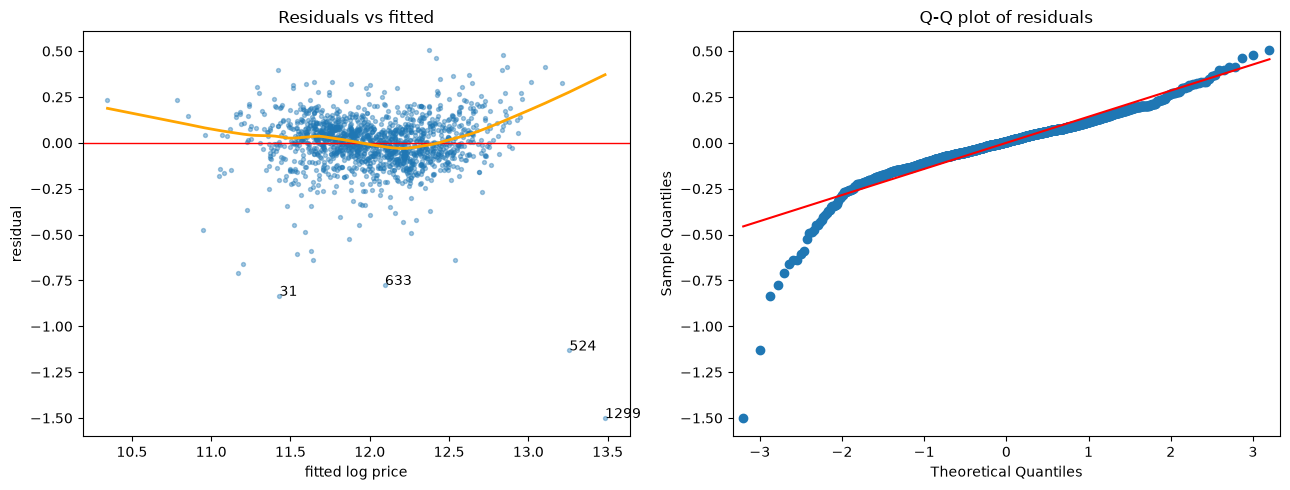

In [4]:
# Residuals vs fitted (linearity, constant variance) and Q-Q plot (normality)
fitted, resid = ols.fittedvalues, ols.resid

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(fitted, resid, s=8, alpha=0.4)
axes[0].axhline(0, color="red", lw=1)
# Smoothed trend of the residuals: it should stay flat at 0 if the model is linear enough
trend = lowess(resid, fitted, frac=0.3)
axes[0].plot(trend[:, 0], trend[:, 1], color="orange", lw=2)
# Label the 4 largest residuals with their Id
for i in np.argsort(np.abs(resid.to_numpy()))[-4:]:
    axes[0].annotate(str(train["Id"].iloc[i]), (fitted.iloc[i], resid.iloc[i]))
axes[0].set(xlabel="fitted log price", ylabel="residual", title="Residuals vs fitted")

sm.qqplot(resid, line="s", ax=axes[1])
axes[1].set_title("Q-Q plot of residuals")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_residuals_qq.png", dpi=150, bbox_inches="tight")
plt.show()

Most residuals sit in a flat band around 0, but the orange trend curves up at both ends. The model under-predicts the cheapest and the most expensive houses, which means the relationship isn't perfectly linear at the extremes.

The two big misses are 1299 and 524 again: predicted around 13.5 and 13.3 in log price (roughly \$715k and \$575k) when they sold for \$160k and \$185k, so 3 to 4.5 times too high. 31 and 633 are cheap houses that also sold well below the prediction.

The Q-Q plot is almost straight on the right but drops sharply on the left: about a dozen houses sold far below what their features suggest. That's the heavy left tail from Jarque-Bera. Non-normal residuals matter for p-values and intervals, not for the predictions themselves, and with 1,460 houses the p-values are fairly robust anyway.

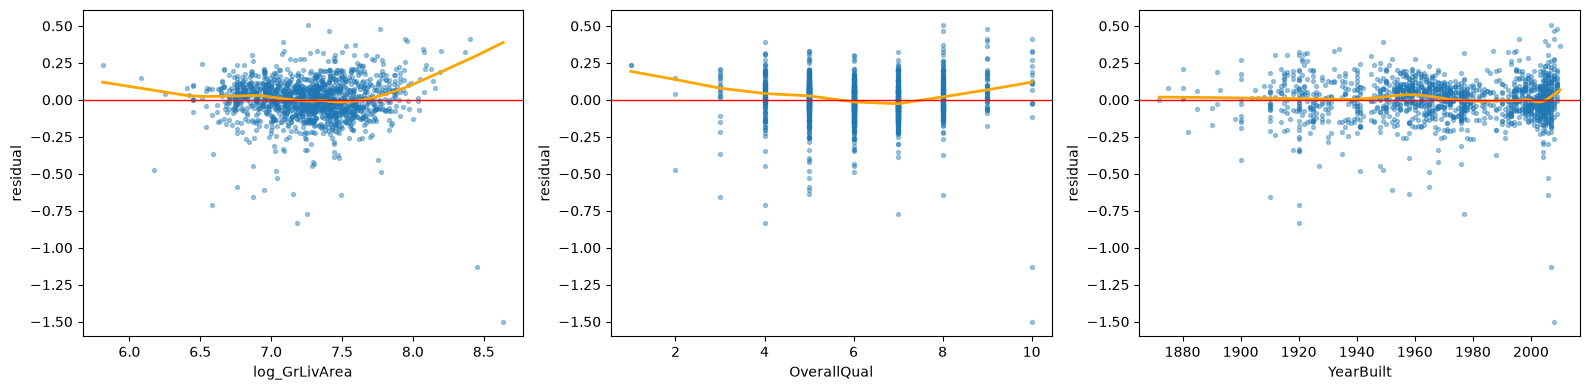

In [5]:
# Residuals vs the strongest features: a curved trend means a missing non-linearity
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["log_GrLivArea", "OverallQual", "YearBuilt"]):
    ax.scatter(Xs[col], resid, s=8, alpha=0.4)
    t = lowess(resid, Xs[col], frac=0.3)
    ax.plot(t[:, 0], t[:, 1], color="orange", lw=2)
    ax.axhline(0, color="red", lw=1)
    ax.set(xlabel=col, ylabel="residual")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_residuals_vs_features.png", dpi=150, bbox_inches="tight")
plt.show()

log_GrLivArea: flat in the middle, but the trend rises for the largest houses (above about 8.0, roughly 3,000 sq ft). Big houses are under-predicted, apart from the two outliers at the bottom right.

OverallQual: a U shape. The model under-predicts both the lowest (1 to 3) and highest (9 to 10) quality houses. The effect of quality is stronger at the extremes than a straight line allows, which matches the bigger steps at the top that I saw in the EDA.

YearBuilt: flat, with a small rise for the newest houses.

The fix for these curves would be a squared term, splines or an interaction (like QualxArea). Tree models pick this up on their own.

In [6]:
# Formal tests: constant variance, normality, independence
bp_p = het_breuschpagan(resid, Xc)[1]
jb_stat, jb_p, skew, kurt = jarque_bera(resid)
print(f"Breusch-Pagan p = {bp_p:.2g}   (small p: the variance is not constant)")
print(f"Jarque-Bera   p = {jb_p:.2g}   | skew {skew:.2f}, kurtosis {kurt:.2f} (normal: 0 and 3)")

# Durbin-Watson depends on row order: file order vs grouped by neighborhood
order = train["Neighborhood"].sort_values(kind="stable").index
print(f"Durbin-Watson, file order:            {durbin_watson(resid):.3f}")
print(f"Durbin-Watson, sorted by neighborhood: {durbin_watson(resid.loc[order]):.3f}")

# Average residual per neighborhood: is the model systematically off in some places?
by_nbhd = resid.groupby(train["Neighborhood"]).agg(["mean", "count"]).sort_values("mean")
print("\nMost over-predicted neighborhoods:\n", by_nbhd.head(5).round(3))
print("\nMost under-predicted neighborhoods:\n", by_nbhd.tail(5).round(3))

Breusch-Pagan p = 3e-15   (small p: the variance is not constant)
Jarque-Bera   p = 0   | skew -1.79, kurtosis 16.93 (normal: 0 and 3)
Durbin-Watson, file order:            1.996
Durbin-Watson, sorted by neighborhood: 1.830

Most over-predicted neighborhoods:
                mean  count
Neighborhood              
IDOTRR       -0.093     37
Gilbert      -0.063     79
OldTown      -0.048    113
NWAmes       -0.047     73
MeadowV      -0.043     17

Most under-predicted neighborhoods:
                mean  count
Neighborhood              
Veenker       0.052     11
NridgHt       0.061     77
NoRidge       0.081     41
Crawfor       0.110     51
StoneBr       0.135     25


Breusch-Pagan p = 3e-15: the variance of the residuals is not constant, even with the log target. With 1,460 houses the test catches even small differences, and the outliers add to it, but it's still a real violation. So for p-values I should use robust standard errors (HC3), checked below.

Jarque-Bera p = 0: not normal, because of the heavy left tail.

Durbin-Watson is 1.996 in file order. That only says rows next to each other in the file aren't related, which tells me little, because the file order means nothing. Sorted by neighborhood it drops to 1.83, so houses in the same neighborhood have similar residuals. The errors are clustered by location.

The neighborhood averages show it clearly. The model under-predicts StoneBr by about 13.5%, Crawfor by 11% and NoRidge by 8%, and over-predicts IDOTRR by 9% and Gilbert by 6%. Location adds a premium or discount that these 17 features don't capture, because Neighborhood isn't in the subset. Leaving it out can also bias the other coefficients: features that go along with good neighborhoods (quality, age) pick up part of the location effect.

In [7]:
# Multicollinearity: VIF per feature and the condition number
vif = pd.Series(
    [variance_inflation_factor(Xc.to_numpy(dtype=float), i) for i in range(1, Xc.shape[1])],
    index=Xs.columns,
).sort_values(ascending=False)
print(vif.round(1).to_string())

print("\ncondition number, raw features:         ", round(ols.condition_number))
Xz = (Xs - Xs.mean()) / Xs.std()
print("condition number, standardized features:", round(np.linalg.cond(sm.add_constant(Xz))))

log_GrLivArea        6.3
GarageCars           5.3
GarageArea           4.9
BsmtQual             4.6
YearBuilt            4.0
OverallQual          3.7
TotRmsAbvGrd         3.4
ExterQual            2.9
log1p_TotalBsmtSF    2.7
FullBath             2.6
KitchenQual          2.6
YearRemodAdd         2.4
OverallCond          1.6
HalfBath             1.5
Fireplaces           1.5
CentralAir_Y         1.4
log_LotArea          1.4

condition number, raw features:          498563
condition number, standardized features: 8


The highest VIF is 6.3 (log_GrLivArea), then GarageCars 5.3 and GarageArea 4.9. That's in the "worth watching" zone (5 to 10), nothing above 10. So multicollinearity is moderate here: it affects a few coefficients (see the garage cell) but it isn't extreme.

The condition number is 498,563 on the raw features but 8 after standardizing. The warning in the summary came from scale (YearBuilt is around 2000 while most features are below 10), not from features being redundant. A condition number is only meaningful on standardized features, where values above 30 would be a concern.

  Id  cooks_d  leverage  stud_resid  GrLivArea  SalePrice SaleCondition
1299    0.530     0.074     -11.362       5642     160000       Partial
 524    0.057     0.016      -8.146       4676     184750       Partial
  31    0.028     0.015      -5.935       1317      40000        Normal
 813    0.025     0.024      -4.313       1044      55993        Alloca
 496    0.024     0.017      -5.049        720      34900       Abnorml
 969    0.022     0.018      -4.674        968      37900       Abnorml
 917    0.021     0.032      -3.396        480      35311       Abnorml
1454    0.016     0.021      -3.728       1140      84500       Abnorml
 589    0.016     0.031      -2.996       1473     143000       Partial
 633    0.014     0.008      -5.488       1411      82500        Family
rule of thumb 4/n = 0.0027


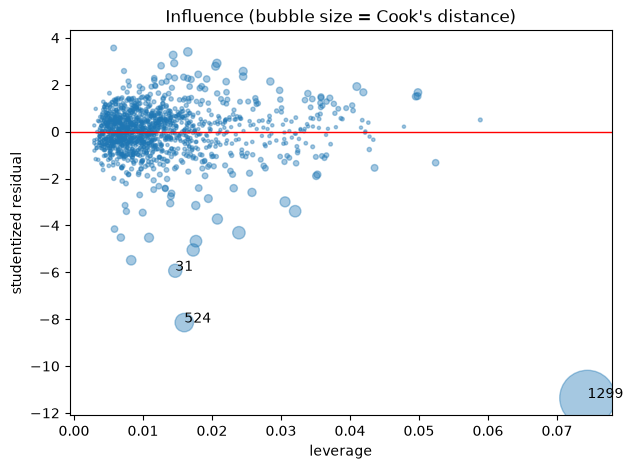

In [8]:
# Influential points: Cook's distance, leverage and studentized residuals
infl = ols.get_influence()
cooks = infl.cooks_distance[0]
lev = infl.hat_matrix_diag
stud = infl.resid_studentized_external

top = pd.DataFrame({
    "Id": train["Id"], "cooks_d": cooks, "leverage": lev, "stud_resid": stud,
    "GrLivArea": train["GrLivArea"], "SalePrice": train["SalePrice"],
    "SaleCondition": train["SaleCondition"],
}).nlargest(10, "cooks_d")
print(top.round(3).to_string(index=False))
print("rule of thumb 4/n =", round(4 / len(y), 4))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(lev, stud, s=5 + 3000 * cooks, alpha=0.4)
for _, r in top.head(3).iterrows():
    i = train.index[train["Id"] == r["Id"]][0]
    ax.annotate(str(int(r["Id"])), (lev[i], stud[i]))
ax.axhline(0, color="red", lw=1)
ax.set(xlabel="leverage", ylabel="studentized residual", title="Influence (bubble size = Cook's distance)")
fig.savefig(FIGURES_DIR / "04_influence.png", dpi=150, bbox_inches="tight")
plt.show()

House 1299 dominates. Its Cook's distance is 0.53, about 10 times the next house and 200 times the 4/n rule of thumb (0.0027). It has both the highest leverage (an unusual combination of features: the largest house) and a huge residual (studentized -11.4). That combination is what makes a point pull the whole fitted line toward itself. 524 is second: a huge residual but ordinary leverage.

The next ones are cheap houses that sold below their prediction: 31 (\$40,000), 496 (\$34,900, the cheapest house in the data), 969, 917, 813, 1454, 633.

Almost all of them are unusual sales: Partial, Abnorml, Family, Alloca. Only 31 is a normal sale. The model's worst errors come from transactions that aren't regular market sales, which is something to check again in error analysis.

In the plot, 1299 sits alone at the bottom right: high leverage and a huge residual. Points with high leverage but small residuals (on the right near 0) are harmless.

In [9]:
# Robust standard errors (HC3): same coefficients, p-values that don't assume constant variance
ols_hc3 = sm.OLS(y, Xc).fit(cov_type="HC3")
comp = pd.DataFrame({
    "coef": ols.params,
    "p_classic": ols.pvalues,
    "p_HC3": ols_hc3.pvalues,
}).drop("const")
print(comp.round(4).to_string())

                     coef  p_classic   p_HC3
OverallQual        0.0653     0.0000  0.0000
OverallCond        0.0490     0.0000  0.0000
log_GrLivArea      0.4101     0.0000  0.0000
log1p_TotalBsmtSF  0.0134     0.0136  0.0100
log_LotArea        0.1135     0.0000  0.0000
GarageCars         0.0496     0.0000  0.0944
GarageArea         0.0001     0.1510  0.5648
YearBuilt          0.0030     0.0000  0.0000
YearRemodAdd       0.0003     0.2917  0.2777
FullBath          -0.0094     0.3950  0.4749
HalfBath          -0.0225     0.0144  0.0114
TotRmsAbvGrd      -0.0050     0.2443  0.2914
Fireplaces         0.0490     0.0000  0.0000
KitchenQual        0.0439     0.0000  0.0000
ExterQual          0.0364     0.0012  0.0021
BsmtQual           0.0279     0.0023  0.0016
CentralAir_Y       0.0594     0.0010  0.0168


The coefficients are identical; only the standard errors change. Since Breusch-Pagan showed the variance isn't constant, these HC3 p-values are the ones to trust.

Most conclusions hold, but three change:
- GarageCars: p from 0.0000 to 0.094, no longer significant at 5%
- GarageArea: p from 0.15 to 0.56
- CentralAir_Y: p from 0.001 to 0.017, weaker but still significant

So the garage effect looked very certain only because the classic formula assumes constant variance. HC3 also gives less weight to high-leverage houses like 1299.

In [10]:
# Reading the coefficients with a log target:
# raw feature -> (exp(coef) - 1) * 100 = % change in price per unit
# log feature -> coef is an elasticity: 1% more of the feature -> coef % higher price
interp = pd.DataFrame({
    "coef": ols.params,
    "pct_per_unit": (np.exp(ols.params) - 1) * 100,
    "p_value": ols.pvalues,
}).drop("const")
print(interp.sort_values("pct_per_unit", ascending=False).round(4).to_string())

                     coef  pct_per_unit  p_value
log_GrLivArea      0.4101       50.6940   0.0000
log_LotArea        0.1135       12.0161   0.0000
OverallQual        0.0653        6.7529   0.0000
CentralAir_Y       0.0594        6.1252   0.0010
GarageCars         0.0496        5.0822   0.0000
Fireplaces         0.0490        5.0256   0.0000
OverallCond        0.0490        5.0182   0.0000
KitchenQual        0.0439        4.4912   0.0000
ExterQual          0.0364        3.7032   0.0012
BsmtQual           0.0279        2.8298   0.0023
log1p_TotalBsmtSF  0.0134        1.3465   0.0136
YearBuilt          0.0030        0.2991   0.0000
YearRemodAdd       0.0003        0.0297   0.2917
GarageArea         0.0001        0.0056   0.1510
TotRmsAbvGrd      -0.0050       -0.4961   0.2443
FullBath          -0.0094       -0.9367   0.3950
HalfBath          -0.0225       -2.2297   0.0144


Three coefficients in plain English, each holding the other features fixed:
- log_GrLivArea 0.41 is an elasticity: 10% more living area means about 4% higher price. (The pct_per_unit column is meaningless for logged features; +1 in log area means 2.7 times the area.)
- OverallQual 0.065: one more quality point means about 6.8% higher price. In the EDA one point looked like 22% to 35%, but there quality was also standing in for size, age and garage. Once those are in the model, the quality effect on its own is much smaller.
- CentralAir_Y 0.059: houses with central air sell about 6% higher.

Also: a 10% bigger lot is about +1.1%, each fireplace about +5%, and a house built 10 years later about +3%.

What I'd tell a business user: these are associations in this data, not causes. Installing central air won't necessarily add 6% to a price, because houses with central air also differ in ways the model doesn't see. And the coefficients only make sense together: "more bathrooms lowers the price" is only true for the same living area.

In [11]:
# GarageCars vs GarageArea: the same information twice
base = [c for c in Xs.columns if c not in ("GarageCars", "GarageArea")]
for cols in (["GarageCars"], ["GarageArea"], ["GarageCars", "GarageArea"]):
    r = sm.OLS(y, sm.add_constant(Xs[base + cols])).fit()
    print(f"{' + '.join(cols):24s} coef {r.params[cols].round(5).to_dict()} "
          f"| SE {r.bse[cols].round(5).to_dict()} | p {r.pvalues[cols].round(4).to_dict()}")

GarageCars               coef {'GarageCars': 0.06276} | SE {'GarageCars': 0.00699} | p {'GarageCars': 0.0}
GarageArea               coef {'GarageArea': 0.00019} | SE {'GarageArea': 2e-05} | p {'GarageArea': 0.0}
GarageCars + GarageArea  coef {'GarageCars': 0.04957, 'GarageArea': 6e-05} | SE {'GarageCars': 0.01153, 'GarageArea': 4e-05} | p {'GarageCars': 0.0, 'GarageArea': 0.151}


Each feature on its own is clearly significant: GarageCars +6.3% per car (SE 0.007), GarageArea +0.019% per sq ft (SE 0.00002). They also agree with each other: one car space is about 250 to 300 sq ft, and 0.00019 × 270 ≈ 0.05.

Put both in and the standard errors grow: about 1.6 times for GarageCars and 2 times for GarageArea. GarageArea becomes "not significant" (p = 0.15).

That's multicollinearity in one picture. GarageArea didn't stop mattering; the model just can't separate its effect from GarageCars when they carry the same information. The predictions barely change, only the split of credit between the two. It's also why a high p-value doesn't mean a feature is useless.

In [12]:
# R² vs adjusted R²: add a column of pure noise
rng = np.random.default_rng(SEED)
r_noise = sm.OLS(y, Xc.assign(noise=rng.normal(size=len(Xc)))).fit()
print(f"R²      {ols.rsquared:.5f} -> {r_noise.rsquared:.5f}")
print(f"adj R²  {ols.rsquared_adj:.5f} -> {r_noise.rsquared_adj:.5f}")
print(f"p-value of the noise column: {r_noise.pvalues['noise']:.3f}")

R²      0.87294 -> 0.87300
adj R²  0.87144 -> 0.87142
p-value of the noise column: 0.388


A column of random noise still raises R² (0.87294 to 0.87300). OLS can always set the new coefficient to 0 and get the old fit back, so adding a feature can never make the training fit worse. Adjusted R² goes down (0.87144 to 0.87142) because it charges for the extra parameter. The noise column's p-value is 0.39, correctly not significant.

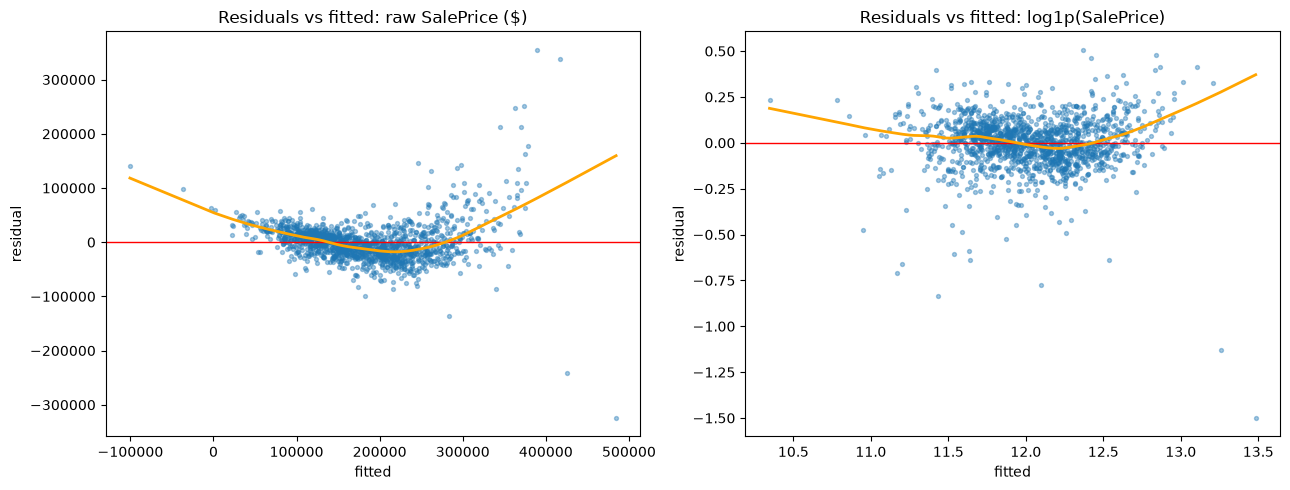

raw target: Breusch-Pagan p = 2.4e-28 | R² = 0.790
log target: Breusch-Pagan p = 3e-15 | R² = 0.873


In [13]:
# The same model WITHOUT the log target: residuals side by side
ols_raw = sm.OLS(train["SalePrice"], Xc).fit()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (res, title) in zip(axes, [(ols_raw, "raw SalePrice ($)"), (ols, "log1p(SalePrice)")]):
    ax.scatter(res.fittedvalues, res.resid, s=8, alpha=0.4)
    ax.axhline(0, color="red", lw=1)
    t = lowess(res.resid, res.fittedvalues, frac=0.3)
    ax.plot(t[:, 0], t[:, 1], color="orange", lw=2)
    ax.set(xlabel="fitted", ylabel="residual", title=f"Residuals vs fitted: {title}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_raw_vs_log_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

for name, res in [("raw target", ols_raw), ("log target", ols)]:
    print(f"{name}: Breusch-Pagan p = {het_breuschpagan(res.resid, Xc)[1]:.2g} | R² = {res.rsquared:.3f}")

This is the visual proof for the log target.

With raw prices, the residuals form a clear U-shaped curve and a funnel: errors of about ±50k for houses around \$150k, and ±300k for the expensive ones. The model even predicts negative prices for a few houses (fitted values below 0), which is impossible.

With the log target the band is much flatter and the spread is far more even. Breusch-Pagan goes from 2.4e-28 to 3e-15, still not perfect but much better, and R² goes from 0.79 to 0.87. (R² on two different targets isn't a perfect comparison, but the plots tell the same story.)

In [14]:
# The results table so far
print(show_results().to_string())

   phase                      model                   feature_set  n_features  cv_rmse_mean  cv_rmse_std                                              notes
0      3  Ridge (alpha=10, untuned)                   linear_full         280       0.13155      0.02399  all features, no tuning; reference for Phases 4-5
1      4     OLS (LinearRegression)                    ols_subset          17       0.14603      0.02001              17 hand-picked features, logged areas
2      4     OLS (LinearRegression)                   linear_full         280       0.14948      0.02651                    all features, no regularization
3      3           LinearRegression  OverallQual + log(GrLivArea)           2       0.19946      0.01586                                     quality + size
4      3           LinearRegression                   OverallQual           1       0.23083      0.00692                                       quality only
5      3        Neighborhood median                  Neighborhoo

Ridge (0.1315) is still the best model. OLS on 17 features (0.1460) and on all 280 (0.1495) are both better than every baseline but worse than Ridge.

## Where I am after Phase 4

How the assumptions hold up:
- Linearity: mostly fine, but quality and living area have stronger effects at the extremes (U-shaped residuals).
- Independence: residuals cluster by neighborhood, because Neighborhood isn't in the 17 features.
- Constant variance: violated even with the log target (much better than raw prices), so I use HC3 for p-values.
- Normality: heavy left tail from houses that sold far below their prediction, mostly unusual sales. This affects p-values, not predictions.
- Multicollinearity: moderate (VIF up to 6.3). It mainly makes the garage coefficients unreliable.
- Influential points: 1299 dominates (Cook's D 0.53), then 524.

For prediction, OLS works but loses to Ridge, especially with all 280 features, where the unregularized coefficients get noisy.

Next, Phase 5: Ridge, Lasso and Elastic Net with tuned alpha, the validation curve, coefficient paths, and the outlier experiment with and without 524 and 1299.